In [5]:
%run ./xraymodel.ipynb

c:\Users\lisar\miniconda3\envs\error-explorer\Lib\site-packages\nbformat\validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


found 1695 images


ModuleNotFoundError: No module named 'lime'

ModuleNotFoundError: No module named 'lime'

In [6]:
import numpy as np
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt

In [7]:
def get_queryidx(pathology: str, dataset_label_idx, NIH_labels, predictions): #, errors: str):

    idx = dataset_label_idx[pathology]

    y = NIH_labels[:,idx]
    pred = predictions[:, idx]

    #match errors:
    #    case "fp":
    #        indices = np.where((y == 0) & (pred >= 0.5))
    #    case "tp":
    #        indices = np.where((y == 1) & (pred >= 0.5))
    #    case "fn":
    #        indices = np.where((y == 1) & (pred < 0.5))
    #    case "tn":
    #        indices = np.where((y == 0) & (pred < 0.5))
    # return indices[0]

    fp_indices = np.where((y == 0) & (pred >= 0.5))[0]
    tp_indices = np.where((y == 1) & (pred >= 0.5))[0]
    fn_indices = np.where((y == 1) & (pred < 0.5))[0]
    tn_indices = np.where((y == 0) & (pred < 0.5))[0]

    return (fp_indices, tp_indices, fn_indices, tn_indices, y, pred)   


In [8]:
dataset = load_dataset()
images = np.stack([x["img"] for x in dataset])

found 1695 images


In [ ]:
def query_error(error_idx, images):
    query_idx = np.random.default_rng(42).choice(error_idx) # random selection

    # Flatten images for pixel-based comparison
    X = images.reshape(len(images), -1).astype(np.float32)

    nn = NearestNeighbors(n_neighbors=11, metric="euclidean")
    nn.fit(X)

    distances, indices = nn.kneighbors(X[query_idx:query_idx + 1])

    # Exclude query image
    mask = indices[0] != query_idx
    neighbor_indices = indices[0][mask][:10]
    neighbor_distances = distances[0][mask][:10]

    # Query + nearest neighbors
    plot_indices = [query_idx] + list(neighbor_indices)

    return indices, neighbor_indices, neighbor_distances, plot_indices


In [10]:
fp_indices, tp_indices, fn_indices, tn_indices, y, pred = get_queryidx("Pneumothorax", DATASET_LABEL_INDICES, NIH_GOOGLE_LABELS_LIST, MODEL_SCORE_PREDICTIONS)
indices, neighbor_indices, neighbor_distances, plot_indices = query_error(fp_indices, images)

In [11]:
def get_classification(idx):
    if idx in fp_indices: return "FP"
    if idx in tp_indices: return "TP"
    if idx in fn_indices: return "FN"
    if idx in tn_indices: return "TN"
    return "Unknown"

In [12]:

def plot_knn(neighbor_distances, plot_indices, pathology, y, pred):
    fig, axes = plt.subplots(2, 6, figsize=(18, 8))
    axes = axes.flatten()

    for i, img_idx in enumerate(plot_indices):
        axes[i].imshow(images[img_idx, 0], cmap="gray")
        axes[i].axis("off")

        ground_truth = y[img_idx]
        prediction = pred[img_idx]
        classification = get_classification(img_idx)

        if i == 0:
            axes[i].set_title(
                f"Query ({classification})\n"
                f"GT: {ground_truth:.0f} | Pred: {prediction:.3f}",
                color="red",
                fontsize=10
            )
        else:
            axes[i].set_title(
                f"Neighbor {i} ({classification})\n"
                f"Dist: {neighbor_distances[i-1]:,.0f}\n"
                f"GT: {ground_truth:.0f} | Pred: {prediction:.3f}",
                fontsize=10
            )

    # Hide unused subplot
    for ax in axes[len(plot_indices):]:
        ax.axis("off")

    plt.suptitle(f"Nearest Neighbors — {pathology}", fontsize=14)
    plt.tight_layout(h_pad=3)
    plt.show()

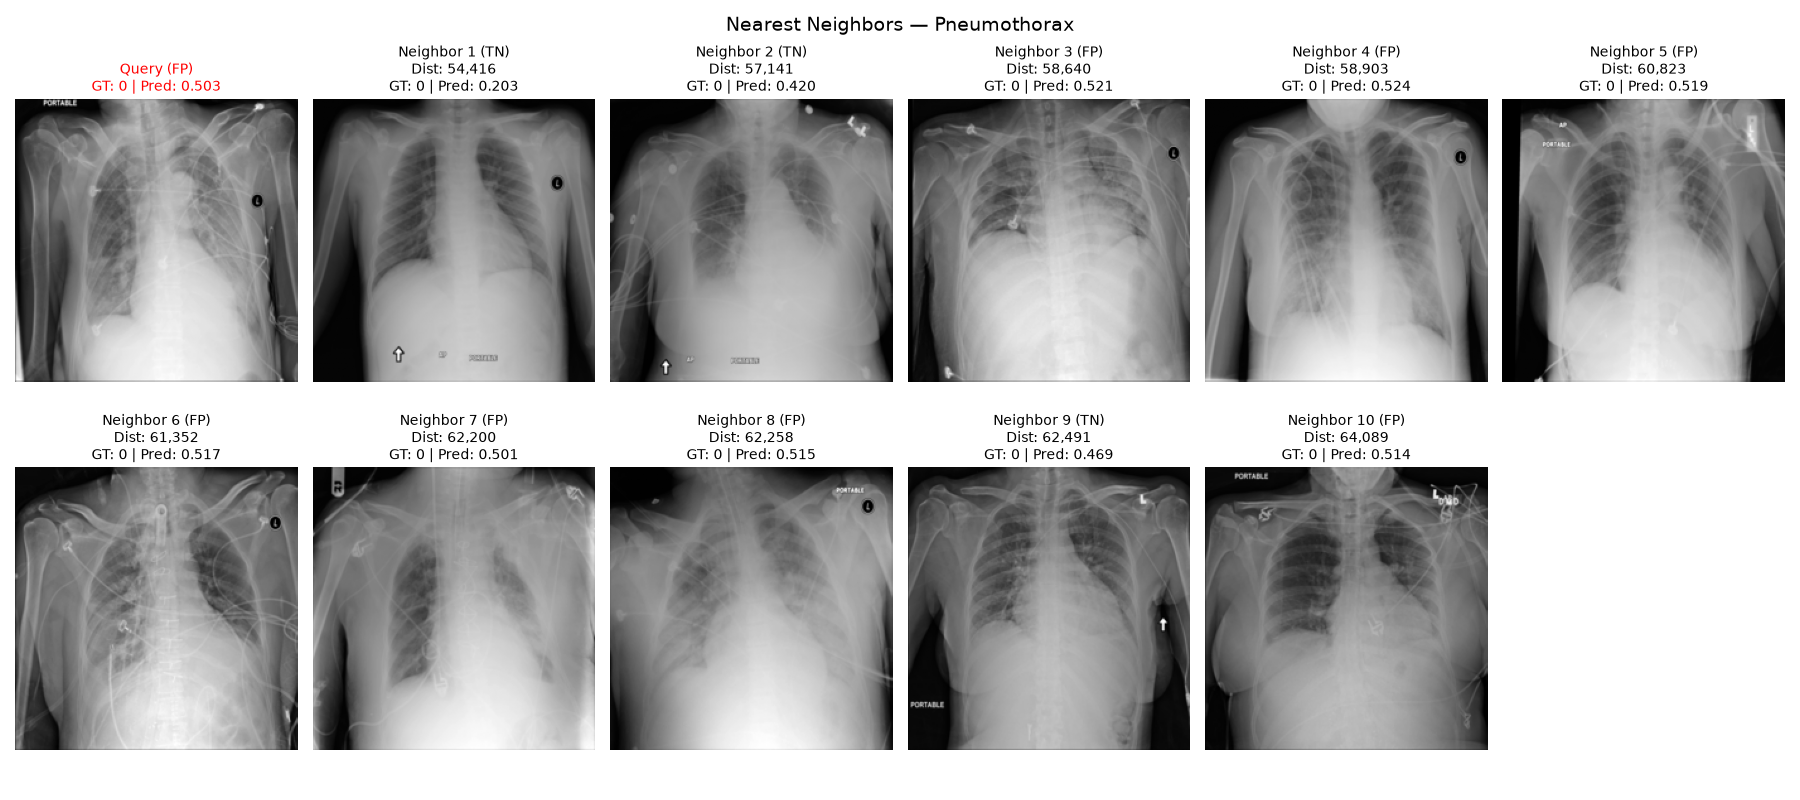

In [13]:
plot_knn(neighbor_distances, plot_indices, "Pneumothorax", y, pred)